In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from ucimlrepo import fetch_ucirepo

In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [5]:
auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets

df = pd.concat([X, y], axis=1)
print(df.head())
print(df.info())
print(df.describe())

   displacement  cylinders  horsepower  weight  acceleration  model_year  \
0         307.0          8       130.0    3504          12.0          70   
1         350.0          8       165.0    3693          11.5          70   
2         318.0          8       150.0    3436          11.0          70   
3         304.0          8       150.0    3433          12.0          70   
4         302.0          8       140.0    3449          10.5          70   

   origin   mpg  
0       1  18.0  
1       1  15.0  
2       1  18.0  
3       1  16.0  
4       1  17.0  
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64 

Пропуски:
 displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64


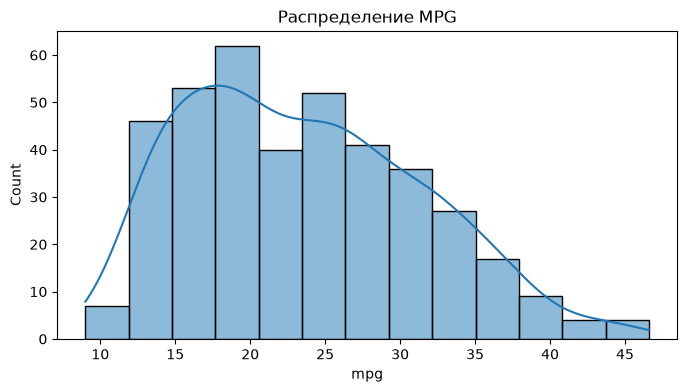

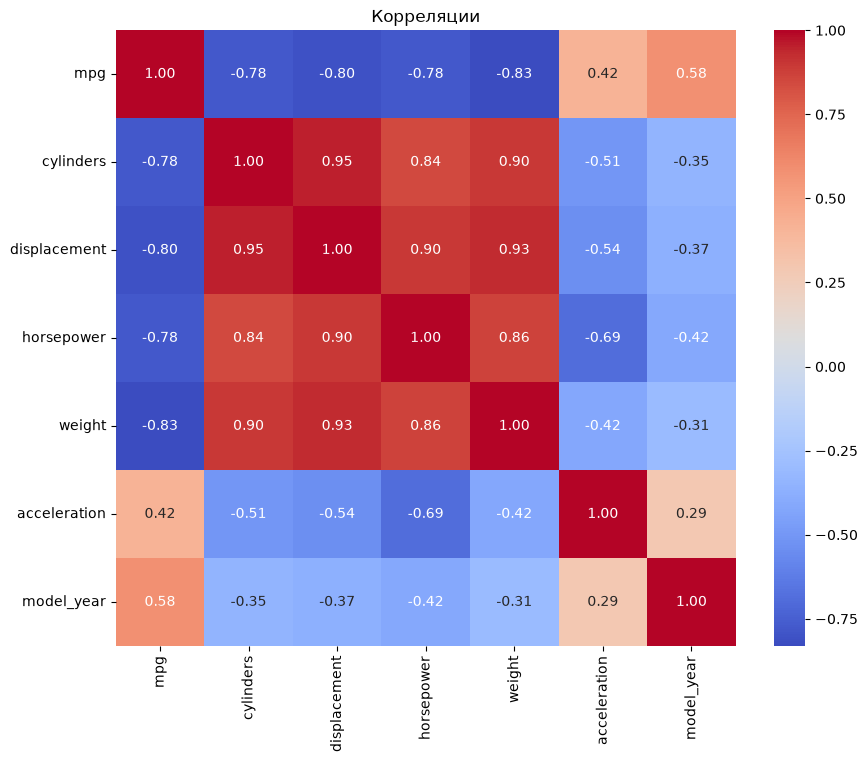

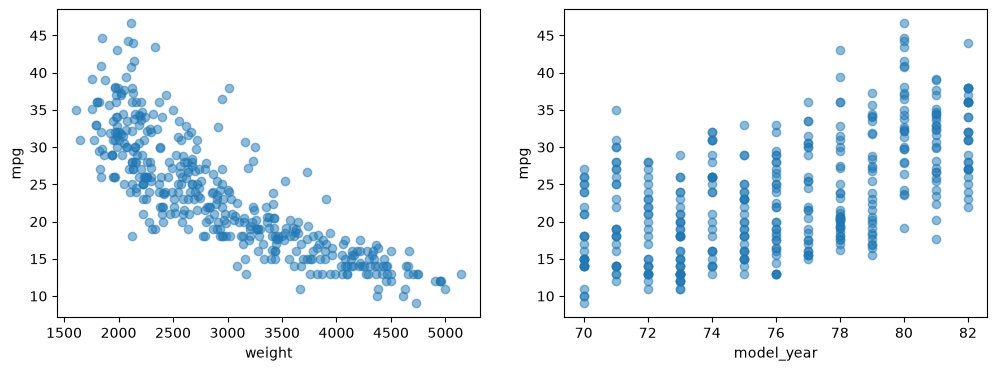

In [6]:
print("Пропуски:\n", df.isna().sum())

df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

plt.figure(figsize=(8, 4))
sns.histplot(df['mpg'], kde=True)
plt.title('Распределение MPG')
plt.show()

num_cols = ['mpg', 'cylinders', 'displacement', 'horsepower',
            'weight', 'acceleration', 'model_year']
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Корреляции')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df['weight'], df['mpg'], alpha=0.5)
axes[0].set_xlabel('weight'); axes[0].set_ylabel('mpg')
axes[1].scatter(df['model_year'], df['mpg'], alpha=0.5)
axes[1].set_xlabel('model_year'); axes[1].set_ylabel('mpg')
plt.show()

In [8]:
# df уже = concat([X, y]) — car_name отсутствует
df_model = df.copy()

# horsepower в ucimlrepo приходит как object из-за '?' — приводим к числу
df_model['horsepower'] = pd.to_numeric(df_model['horsepower'], errors='coerce')
df_model['horsepower'] = df_model['horsepower'].fillna(df_model['horsepower'].median())

feature_cols = ['cylinders', 'displacement', 'horsepower',
                'weight', 'acceleration', 'model_year', 'origin']
target_col = 'mpg'

X = df_model[feature_cols]
y = df_model[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_features = ['cylinders', 'displacement', 'horsepower',
                    'weight', 'acceleration', 'model_year']
categorical_features = ['origin']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ]
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (318, 7), Test: (80, 7)


In [9]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    mae  = mean_absolute_error(y_te, y_pred)
    r2   = r2_score(y_te, y_pred)
    print(f"{name:35s} | RMSE={rmse:.3f} | MAE={mae:.3f} | R2={r2:.3f}")
    return {'name': name, 'model': model, 'rmse': rmse, 'mae': mae, 'r2': r2}

results = []

# 1. Линейная регрессия (без параметров)
pipe_lr = Pipeline([('prep', preprocessor), ('model', LinearRegression())])
results.append(evaluate_model("LinearRegression", pipe_lr, X_train, y_train, X_test, y_test))

# 2. Ridge: перебор alpha
ridge_alphas = [0.01, 0.1, 1, 5, 10, 50, 100]
pipe_ridge = Pipeline([('prep', preprocessor), ('model', Ridge())])
param_grid_ridge = {'model__alpha': ridge_alphas}
grid_ridge = GridSearchCV(pipe_ridge, param_grid_ridge, cv=5, scoring='neg_root_mean_squared_error')
grid_ridge.fit(X_train, y_train)
for alpha in ridge_alphas:
    pipe_r = Pipeline([('prep', preprocessor), ('model', Ridge(alpha=alpha))])
    results.append(evaluate_model(f"Ridge(alpha={alpha})", pipe_r,
                                  X_train, y_train, X_test, y_test))
print("Лучший Ridge по CV:", grid_ridge.best_params_, -grid_ridge.best_score_)

# 3. Lasso: перебор alpha
lasso_alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1]
for alpha in lasso_alphas:
    pipe_l = Pipeline([('prep', preprocessor), ('model', Lasso(alpha=alpha, max_iter=10000))])
    results.append(evaluate_model(f"Lasso(alpha={alpha})", pipe_l,
                                  X_train, y_train, X_test, y_test))

LinearRegression                    | RMSE=2.888 | MAE=2.288 | R2=0.845
Ridge(alpha=0.01)                   | RMSE=2.888 | MAE=2.288 | R2=0.845
Ridge(alpha=0.1)                    | RMSE=2.888 | MAE=2.288 | R2=0.845
Ridge(alpha=1)                      | RMSE=2.889 | MAE=2.288 | R2=0.845
Ridge(alpha=5)                      | RMSE=2.901 | MAE=2.301 | R2=0.843
Ridge(alpha=10)                     | RMSE=2.917 | MAE=2.327 | R2=0.842
Ridge(alpha=50)                     | RMSE=2.979 | MAE=2.387 | R2=0.835
Ridge(alpha=100)                    | RMSE=3.021 | MAE=2.410 | R2=0.830
Лучший Ridge по CV: {'model__alpha': 1} 3.4543374198084846
Lasso(alpha=0.001)                  | RMSE=2.889 | MAE=2.289 | R2=0.845
Lasso(alpha=0.01)                   | RMSE=2.904 | MAE=2.292 | R2=0.843
Lasso(alpha=0.05)                   | RMSE=2.939 | MAE=2.324 | R2=0.839
Lasso(alpha=0.1)                    | RMSE=2.955 | MAE=2.343 | R2=0.838
Lasso(alpha=0.5)                    | RMSE=2.964 | MAE=2.341 | R2=0.837
Lasso

              name     rmse      mae       r2
  LinearRegression 2.887673 2.288159 0.844910
 Ridge(alpha=0.01) 2.887682 2.288158 0.844909
  Ridge(alpha=0.1) 2.887767 2.288149 0.844900
Lasso(alpha=0.001) 2.889107 2.288591 0.844756
    Ridge(alpha=1) 2.889247 2.287844 0.844741
    Ridge(alpha=5) 2.901210 2.301188 0.843452
 Lasso(alpha=0.01) 2.904017 2.292359 0.843149
   Ridge(alpha=10) 2.916598 2.326582 0.841787
 Lasso(alpha=0.05) 2.939183 2.323817 0.839327
  Lasso(alpha=0.1) 2.955299 2.342907 0.837561
  Lasso(alpha=0.5) 2.963682 2.340553 0.836638
   Ridge(alpha=50) 2.978955 2.387378 0.834950
    Lasso(alpha=1) 3.001748 2.302569 0.832414
  Ridge(alpha=100) 3.020869 2.410098 0.830272


C:\Users\goblin\AppData\Local\Temp\ipykernel_5164\1035986707.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='rmse', y='name', palette='viridis')


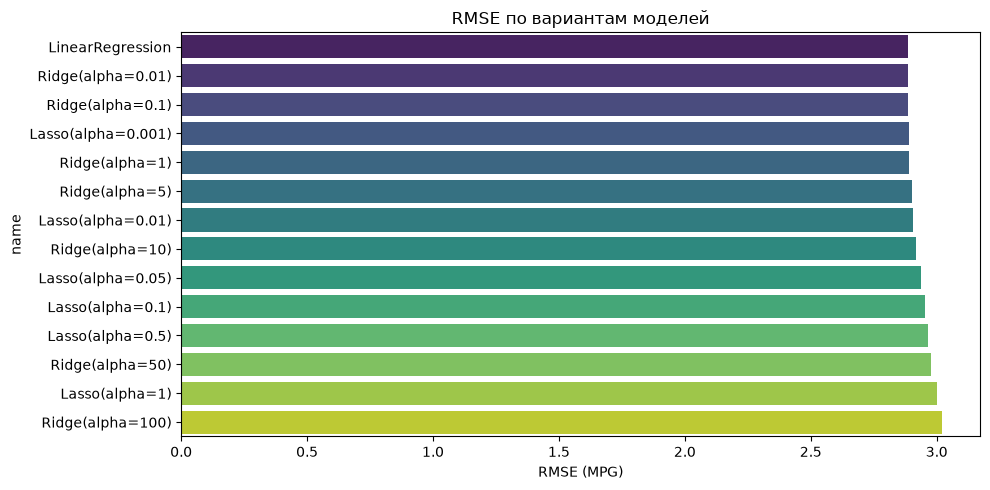

In [10]:
res_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'model'} for r in results])
res_df = res_df.sort_values('rmse')
print(res_df.to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=res_df, x='rmse', y='name', palette='viridis')
plt.title('RMSE по вариантам моделей')
plt.xlabel('RMSE (MPG)')
plt.tight_layout()
plt.show()

Лучшая модель: LinearRegression | RMSE=2.888 | R2=0.845
Прогноз MPG для нового авто: 32.27


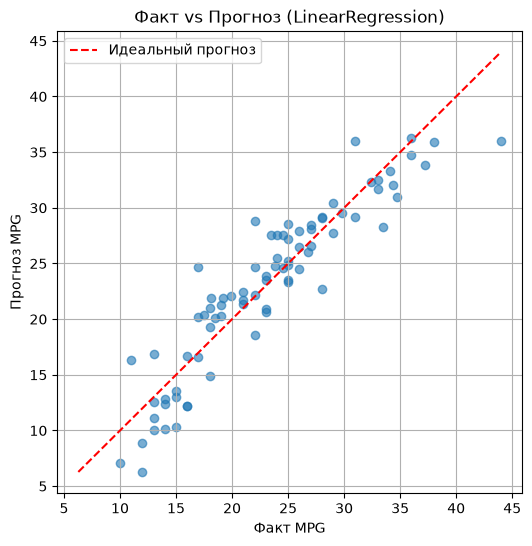

In [11]:
best = min(results, key=lambda r: r['rmse'])
best_model = best['model']
print(f"Лучшая модель: {best['name']} | RMSE={best['rmse']:.3f} | R2={best['r2']:.3f}")

y_pred = best_model.predict(X_test)

new_car = pd.DataFrame([{
    'cylinders': 4,
    'displacement': 120.0,
    'horsepower': 95.0,
    'weight': 2500.0,
    'acceleration': 15.0,
    'model_year': 82,
    'origin': 3
}])
pred_mpg = best_model.predict(new_car)[0]
print(f"Прогноз MPG для нового авто: {pred_mpg:.2f}")


plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Идеальный прогноз')
plt.xlabel('Факт MPG'); plt.ylabel('Прогноз MPG')
plt.title(f"Факт vs Прогноз ({best['name']})")
plt.legend(); plt.grid(True)
plt.show()